# 05.02 Logistic Regression Baseline (Patient-Grouped 10-Fold CV)

### Model Pipeline Architecture
```mermaid
flowchart LR
    A["Authentic & Synthetic Splits"] --> B["ColumnTransformer"]
    B --> C["Numeric: Median Impute + StandardScaler"]
    B --> D["Categorical: Constant Impute + OneHotEncoder"]
    C & D --> E["LogisticRegression (C=0.5, balanced)"]
    E --> F["10-Fold Patient-Grouped OOF"]
    F --> G["Track A vs Track B Comparison & Diagnostics"]
```

## 1. Environment Setup & Dataset Loading

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, brier_score_loss, log_loss, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
)
from sklearn.calibration import CalibrationDisplay
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_SEED = 42

def find_project_root() -> Path:
    cur = Path.cwd().resolve()
    for p in [cur] + list(cur.parents):
        if (p / "data").exists() and (p / "experiments").exists():
            return p
    return cur

PROJECT_ROOT = find_project_root()
MODELS_DIR = PROJECT_ROOT / "models" / "phase_05"
REPORTS_DIR = PROJECT_ROOT / "reports" / "phase_05"
VIZ_DIR = REPORTS_DIR / "visualizations" / "logistic_regression"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
VIZ_DIR.mkdir(parents=True, exist_ok=True)

split = json.loads((MODELS_DIR / "phase05_split_and_schema.json").read_text(encoding="utf-8"))
df_auth = pd.read_csv(PROJECT_ROOT / split["dataset_authentic"])
df_syn = pd.read_csv(PROJECT_ROOT / split["dataset_synthetic"])

NUM_COLS = split["num_cols"]
CAT_COLS = split["cat_cols"]
FEATURE_COLS = split["feature_cols"]

df_tr_dev = df_auth.iloc[split["auth_train_indices"]].reset_index(drop=True)
X_dev = df_tr_dev[FEATURE_COLS].copy()
y_dev = df_tr_dev["target"].to_numpy(dtype=int)
folds = split["cv_folds"]

print(f"Authentic Train-Dev Patients : {len(X_dev)}")
print(f"Numeric Features ({len(NUM_COLS)}) : {NUM_COLS}")
print(f"Categorical Features ({len(CAT_COLS)}) : {CAT_COLS}")
print(f"Target Balance (Eligible=1)  : {y_dev.mean():.2%}")

Authentic Train-Dev Patients : 95
Numeric Features (7) : ['age', 'household_size', 'number_of_dependents', 'monthly_family_income', 'monthly_household_obligations_expenses', 'monthly_utility_expenses', 'cost_of_treatment']
Categorical Features (20) : ['sex', 'marital_status', 'employment_status', 'residence_status', 'educational_attainment', 'housing_condition', 'sectoral_membership', 'disability_status', 'diagnosis_severity', 'type_of_treatment_surgery', 'laterality', 'patient_clinical_type', 'assistance_type', 'certificate_of_indigency', 'proof_of_income_employment', 'government_id', 'utility_bill_document', 'referral_letter', 'philhealth_document', 'medical_record_diagnosis_treatment_plan']
Target Balance (Eligible=1)  : 63.16%


## 2. Evaluation Metrics Helper & Logistic Regression Pipeline

In [2]:
def compute_binary_metrics(y_true, y_prob, threshold=0.5):
    y_t = np.asarray(y_true, dtype=int)
    y_p = np.clip(np.asarray(y_prob, dtype=float), 1e-7, 1.0 - 1e-7)
    y_pred = (y_p >= threshold).astype(int)
    cm = confusion_matrix(y_t, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    bal_acc = 0.5 * (spec + rec)
    bins = np.linspace(0.0, 1.0, 11)
    ece = 0.0
    for i in range(10):
        m = (y_p >= bins[i]) & (y_p < bins[i + 1] if i < 9 else y_p <= bins[i + 1])
        if m.any():
            ece += (m.sum() / len(y_t)) * abs(y_t[m].mean() - y_p[m].mean())
    auc = float(roc_auc_score(y_t, y_p)) if len(np.unique(y_t)) == 2 else float("nan")
    return {
        "accuracy": float(accuracy_score(y_t, y_pred)),
        "precision": float(precision_score(y_t, y_pred, pos_label=1, zero_division=0)),
        "recall": float(rec),
        "specificity": float(spec),
        "balanced_accuracy": float(bal_acc),
        "f1": float(f1_score(y_t, y_pred, pos_label=1, zero_division=0)),
        "macro_f1": float(f1_score(y_t, y_pred, average="macro", zero_division=0)),
        "roc_auc": auc,
        "brier_score": float(brier_score_loss(y_t, y_p)),
        "log_loss": float(log_loss(y_t, y_p, labels=[0, 1])),
        "ece": float(ece),
        "confusion_matrix": cm.tolist(),
    }

def build_lr_pipe():
    prep = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_COLS),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="UNRECORDED")), ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=3))]), CAT_COLS),
    ])
    return Pipeline([
        ("prep", prep),
        ("clf", LogisticRegression(C=0.5, max_iter=1000, class_weight="balanced", random_state=RANDOM_SEED)),
    ])

## 3. 10-Fold Patient-Grouped Cross-Validation (Track A vs Track B)

In [3]:
def run_cv(augment_synthetic=False):
    oof_probs = np.zeros(len(y_dev), dtype=float)
    fold_rows = []
    for f in folds:
        tr_i, va_i = f["train_indices"], f["val_indices"]
        X_tr, y_tr = X_dev.iloc[tr_i].copy(), y_dev[tr_i].copy()
        if augment_synthetic:
            tr_pts = set(df_tr_dev.iloc[tr_i]["patient_group_id"])
            va_pts = set(df_tr_dev.iloc[va_i]["patient_group_id"])
            syn_f = df_syn[df_syn["patient_group_id"].isin(tr_pts)]
            assert len(set(syn_f["patient_group_id"]) & va_pts) == 0
            if len(syn_f) > 0:
                X_tr = pd.concat([X_tr, syn_f[FEATURE_COLS]], ignore_index=True)
                y_tr = np.concatenate([y_tr, syn_f["target"].to_numpy(dtype=int)])
        pipe = build_lr_pipe()
        pipe.fit(X_tr, y_tr)
        probs = pipe.predict_proba(X_dev.iloc[va_i])[:, 1]
        oof_probs[va_i] = probs
        m = compute_binary_metrics(y_dev[va_i], probs)
        m["fold"] = f["fold"]
        fold_rows.append(m)
    overall = compute_binary_metrics(y_dev, oof_probs)
    return oof_probs, pd.DataFrame(fold_rows), overall

oof_a, folds_a, overall_a = run_cv(augment_synthetic=False)
oof_b, folds_b, overall_b = run_cv(augment_synthetic=True)

metric_keys = ["accuracy", "balanced_accuracy", "precision", "recall", "specificity", "f1", "macro_f1", "roc_auc", "brier_score", "log_loss", "ece"]
comparison_df = pd.DataFrame({
    "Metric": metric_keys,
    "Track A (Authentic-Only OOF)": [overall_a[k] for k in metric_keys],
    "Track A Fold Mean": [folds_a[k].mean() for k in metric_keys],
    "Track A Fold Std": [folds_a[k].std() for k in metric_keys],
    "Track B (Synthetic-Augmented OOF)": [overall_b[k] for k in metric_keys],
    "Delta (Track B - Track A)": [overall_b[k] - overall_a[k] for k in metric_keys],
})
display(comparison_df.round(4))

,Metric,Track A (Authentic-Only OOF),Track A Fold Mean,Track A Fold Std,Track B (Synthetic-Augmented OOF),Delta (Track B - Track A)
0,accuracy,0.9158,0.9178,0.1039,0.8842,-0.0316
1,balanced_accuracy,0.9155,0.9208,0.1084,0.8786,-0.0369
2,precision,0.9483,0.9550,0.0956,0.9153,-0.0330
3,recall,0.9167,0.9167,0.1179,0.9000,-0.0167
4,specificity,0.9143,0.9250,0.1687,0.8571,-0.0571
5,f1,0.9322,0.9312,0.0896,0.9076,-0.0246
6,macro_f1,0.9105,0.9124,0.1102,0.8763,-0.0342
7,roc_auc,0.9490,0.9417,0.1198,0.9295,-0.0195
8,brier_score,0.0768,0.0754,0.0692,0.0946,0.0178
9,log_loss,0.2592,0.2554,0.1980,0.3470,0.0878


## 4. Final Model Training, Feature Coefficients & Artifact Export

In [4]:
# Fit final Track A & Track B models on full train_dev
lr_final_a = build_lr_pipe().fit(X_dev, y_dev)
joblib.dump(lr_final_a, MODELS_DIR / "logistic_regression_baseline.joblib")

syn_tr = df_syn.iloc[split["syn_train_indices"]]
lr_final_b = build_lr_pipe().fit(
    pd.concat([X_dev, syn_tr[FEATURE_COLS]], ignore_index=True),
    np.concatenate([y_dev, syn_tr["target"].to_numpy(dtype=int)]),
)
joblib.dump(lr_final_b, MODELS_DIR / "logistic_regression_trackB.joblib")

np.save(MODELS_DIR / "lr_oof_probs.npy", oof_a)
np.save(MODELS_DIR / "lr_trackB_oof_probs.npy", oof_b)
folds_a.drop(columns=["confusion_matrix"]).to_csv(REPORTS_DIR / "02_logistic_regression_10fold_cv.csv", index=False)
folds_a.drop(columns=["confusion_matrix"]).to_csv(VIZ_DIR / "evaluation_summary_table.csv", index=False)

# Feature coefficients
feat_names = list(lr_final_a.named_steps["prep"].get_feature_names_out())
coefs = lr_final_a.named_steps["clf"].coef_[0]
df_coef = pd.DataFrame({"feature": feat_names, "coef": coefs, "abs_coef": np.abs(coefs)}).sort_values("abs_coef", ascending=False)
df_coef.to_csv(VIZ_DIR / "feature_coefficients.csv", index=False)
top_feats = df_coef.head(15).to_dict(orient="records")

payload = {
    "model_name": "Logistic Regression",
    "cv_protocol": "10-Fold StratifiedGroupKFold (Authentic Patients)",
    "n_train_dev_patients": int(len(y_dev)),
    "track_a_oof": overall_a,
    "track_a_fold_mean": folds_a.drop(columns=["fold", "confusion_matrix"]).mean().to_dict(),
    "track_a_fold_std": folds_a.drop(columns=["fold", "confusion_matrix"]).std().to_dict(),
    "track_b_oof": overall_b,
    "top_features": top_feats,
}
(MODELS_DIR / "lr_metrics.json").write_text(json.dumps(payload, indent=2), encoding="utf-8")
print("Saved Logistic Regression models, OOF probabilities, and metrics JSON.")

Saved Logistic Regression models, OOF probabilities, and metrics JSON.


## 5. Diagnostic Curves (Confusion Matrix, ROC, PR & Calibration)

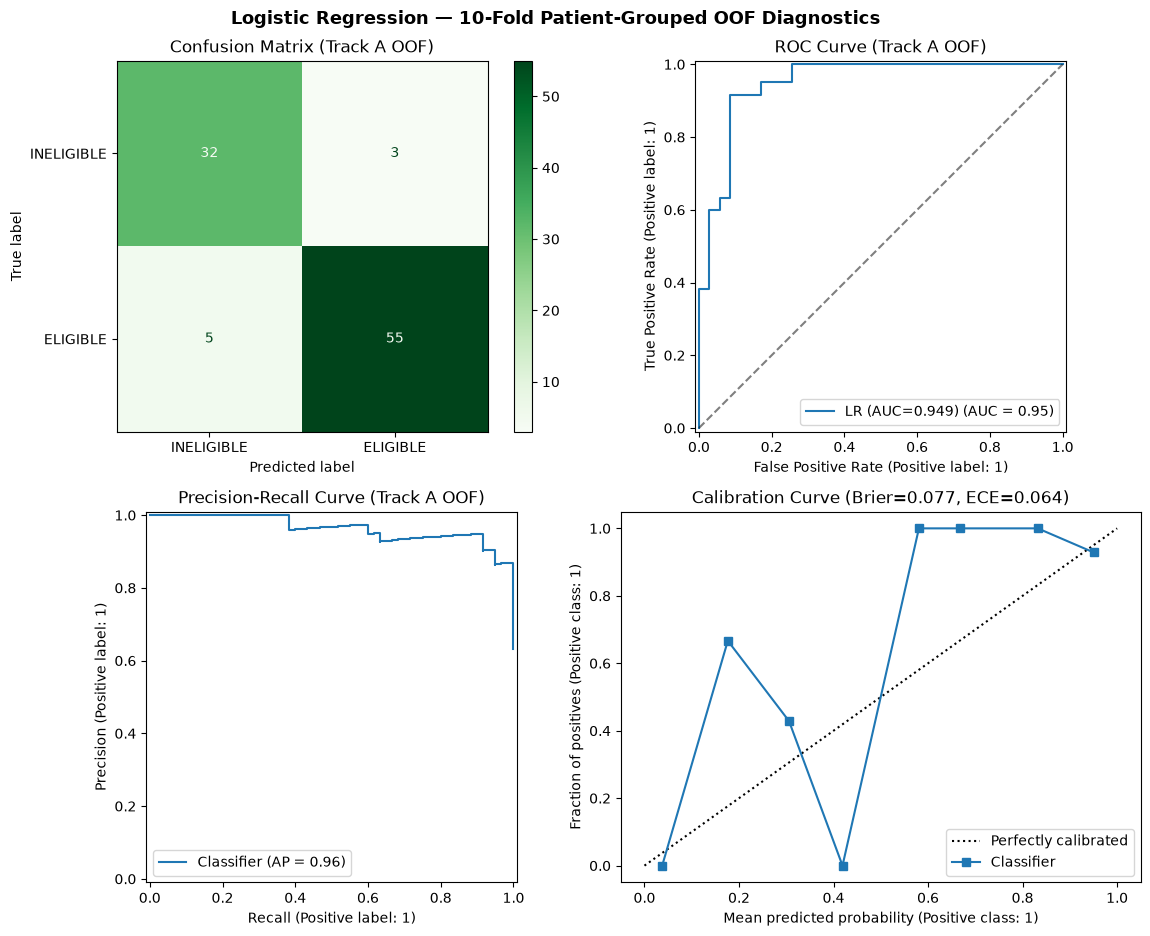

In [5]:
# Save individual legacy reports + unified 2x2 diagnostic dashboard
fig_cm, ax_cm = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_dev, (oof_a >= 0.5).astype(int), display_labels=["INELIGIBLE", "ELIGIBLE"], ax=ax_cm, cmap="Greens")
ax_cm.set_title("Logistic Regression — Track A 10-Fold OOF Confusion Matrix")
plt.tight_layout(); plt.savefig(REPORTS_DIR / "02_lr_confusion_matrix.png", dpi=200); plt.close(fig_cm)

fig, axes = plt.subplots(2, 2, figsize=(12, 9.5))
ConfusionMatrixDisplay.from_predictions(y_dev, (oof_a >= 0.5).astype(int), display_labels=["INELIGIBLE", "ELIGIBLE"], ax=axes[0, 0], cmap="Greens")
axes[0, 0].set_title("Confusion Matrix (Track A OOF)")

RocCurveDisplay.from_predictions(y_dev, oof_a, ax=axes[0, 1], name=f"LR (AUC={overall_a['roc_auc']:.3f})")
axes[0, 1].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0, 1].set_title("ROC Curve (Track A OOF)")

PrecisionRecallDisplay.from_predictions(y_dev, oof_a, ax=axes[1, 0])
axes[1, 0].set_title("Precision-Recall Curve (Track A OOF)")

CalibrationDisplay.from_predictions(y_dev, oof_a, n_bins=8, ax=axes[1, 1])
axes[1, 1].set_title(f"Calibration Curve (Brier={overall_a['brier_score']:.3f}, ECE={overall_a['ece']:.3f})")

fig.suptitle("Logistic Regression — 10-Fold Patient-Grouped OOF Diagnostics", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(REPORTS_DIR / "02_lr_roc_pr_curves.png", dpi=200)
plt.savefig(VIZ_DIR / "confusion_matrix_and_roc.png", dpi=200)
plt.show()

## 6. 10-Fold CV Stability & Track A vs Track B Performance

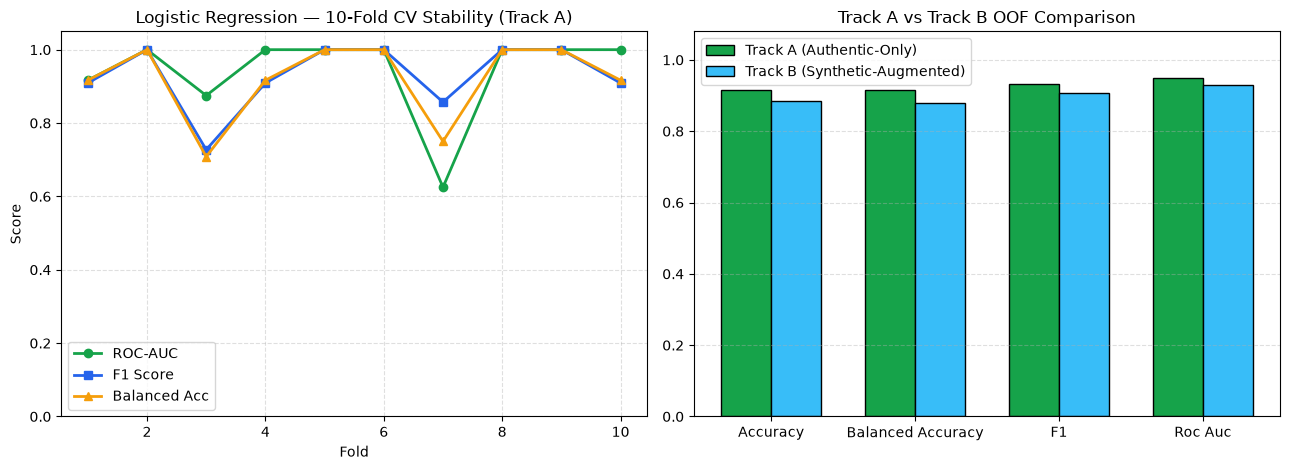

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Left: Per-fold stability
axes[0].plot(folds_a["fold"], folds_a["roc_auc"], marker="o", label="ROC-AUC", linewidth=2, color="#16a34a")
axes[0].plot(folds_a["fold"], folds_a["f1"], marker="s", label="F1 Score", linewidth=2, color="#2563eb")
axes[0].plot(folds_a["fold"], folds_a["balanced_accuracy"], marker="^", label="Balanced Acc", linewidth=2, color="#f59e0b")
axes[0].set_xlabel("Fold")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Logistic Regression — 10-Fold CV Stability (Track A)")
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend()

# Right: Track A vs Track B bar chart
bar_metrics = ["accuracy", "balanced_accuracy", "f1", "roc_auc"]
x = np.arange(len(bar_metrics))
w = 0.35
axes[1].bar(x - w/2, [overall_a[m] for m in bar_metrics], width=w, label="Track A (Authentic-Only)", color="#16a34a", edgecolor="black")
axes[1].bar(x + w/2, [overall_b[m] for m in bar_metrics], width=w, label="Track B (Synthetic-Augmented)", color="#38bdf8", edgecolor="black")
axes[1].set_xticks(x)
axes[1].set_xticklabels([m.replace("_", " ").title() for m in bar_metrics])
axes[1].set_ylim(0, 1.08)
axes[1].set_title("Track A vs Track B OOF Comparison")
axes[1].grid(axis="y", linestyle="--", alpha=0.4)
axes[1].legend()

plt.tight_layout()
plt.savefig(VIZ_DIR / "cv_stability_and_tracks.png", dpi=200)
plt.show()

## 7. Top 12 Standardized Feature Coefficients

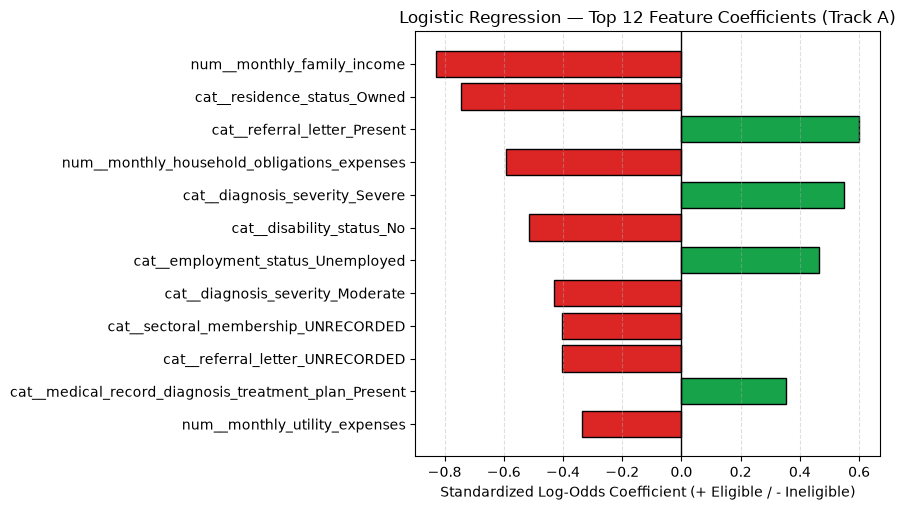

In [7]:
fig, ax = plt.subplots(figsize=(9, 5.2))
top12 = df_coef.head(12).iloc[::-1]
colors = ["#16a34a" if c > 0 else "#dc2626" for c in top12["coef"]]
ax.barh(top12["feature"], top12["coef"], color=colors, edgecolor="black")
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Standardized Log-Odds Coefficient (+ Eligible / - Ineligible)")
ax.set_title("Logistic Regression — Top 12 Feature Coefficients (Track A)")
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(VIZ_DIR / "feature_importance.png", dpi=200)
plt.show()